
# HR Analytics Using Python

## Project Overview
Analyzing HR employee data using Python to understand workforce distribution, hiring trends, employee termination patterns, and data quality.


In [178]:
import pandas as pd

In [179]:
df=pd.read_csv(r"Messy_HR_Dataset_Detailed.csv")

In [180]:
df.shape

(3150, 39)


## Data Loading and Cleaning


In [181]:
df.duplicated().sum()

np.int64(150)

In [182]:
df=df.drop_duplicates()

In [183]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Unnamed: 0                  3000 non-null   int64  
 1   FirstName                   3000 non-null   str    
 2   LastName                    3000 non-null   str    
 3   StartDate                   3000 non-null   str    
 4   ExitDate                    1533 non-null   str    
 5   Title                       3000 non-null   str    
 6   Supervisor                  3000 non-null   str    
 7   ADEmail                     3000 non-null   str    
 8   BusinessUnit                3000 non-null   str    
 9   EmployeeStatus              3000 non-null   str    
 10  EmployeeType                3000 non-null   str    
 11  PayZone                     3000 non-null   str    
 12  EmployeeClassificationType  3000 non-null   str    
 13  TerminationType             3000 non-null   

In [220]:
df.isna().sum()

FirstName                        0
LastName                         0
StartDate                        0
ExitDate                      1467
Title                            0
Supervisor                       0
ADEmail                          0
BusinessUnit                     0
EmployeeStatus                   0
EmployeeType                     0
PayZone                          0
EmployeeClassificationType       0
TerminationType                  0
TerminationDescription        1467
DepartmentType                   0
Division                         0
DOB                              0
State                            0
JobFunctionDescription           0
GenderCode                       0
LocationCode                     0
RaceDesc                         0
MaritalDesc                      0
Performance Score                0
Current Employee Rating          0
Employee ID                      0
Survey Date                      0
Engagement Score                 0
Satisfaction Score  

In [184]:
print(df['Unnamed: 0'].isna().sum())
print(df["Unnamed: 0"].value_counts().sum())

0
3000


In [185]:
df=df.drop(columns=["Unnamed: 0"])

In [219]:
df.head(10)


,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,EmployeeType,...,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Location,Trainer,Training Duration(Days),Training Cost
0,Uriah,Bridges,2019-09-20,NaT,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,Contract,...,2,3,2023-07-15,Leadership Development,Internal,Failed,South Marisa,Taylor Rodriguez,2,606.11
1,Paula,Small,2023-02-11,NaT,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,Contract,...,1,5,2022-09-12,Customer Service,External,Incomplete,Tammieville,Kelly Patterson DDS,4,673.02
2,Edward,Buck,2018-12-10,NaT,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,Full-Time,...,2,1,2022-08-13,Leadership Development,External,Failed,East Roberthaven,Taylor Thomas,2,413.28
3,Michael,Riordan,2021-06-21,NaT,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,Contract,...,5,4,2022-12-15,Project Management,External,Completed,Garzatown,Holly Elliott,3,663.78
4,Jasmine,Onque,2019-06-29,NaT,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,Contract,...,5,3,2023-07-13,Technical Skills,External,Failed,Lake Meganville,Donald Martinez,5,399.03
5,Maruk,Fraval,2020-01-17,NaT,Area Sales Manager,Sheri Campos,maruk.fraval@bilearner.com,BPC,Active,Contract,...,3,5,2023-04-18,Project Management,Internal,Passed,Kingchester,Holly Sloan,2,820.33
6,Latia,Costa,2022-04-06,2023-07-03,Area Sales Manager,Jacob Braun,latia.costa@bilearner.com,WBL,Active,Full-Time,...,5,2,2022-08-06,Customer Service,External,Passed,Lancehaven,David Stewart,5,295.08
7,Sharlene,Terry,2020-11-06,2023-01-29,Area Sales Manager,Tracy Marquez,sharlene.terry@bilearner.com,CCDR,Active,Contract,...,4,2,2022-10-07,Leadership Development,Internal,Passed,Jeremyshire,Stephanie Garza,3,790.15
8,Jac,McKinzie,2018-08-18,NaT,Area Sales Manager,Sharon Becker,jac.mckinzie@bilearner.com,NEL,Active,Contract,...,3,3,2023-07-19,Customer Service,Internal,Passed,West Randall,John Brown,3,798.40
9,Joseph,Martins,2022-01-21,2023-06-29,Area Sales Manager,George Jenkins,joseph.martins@bilearner.com,BPC,Active,Part-Time,...,5,2,2023-04-09,Leadership Development,Internal,Failed,Nicolebury,Megan Wilson,5,192.61


In [187]:
date_formats = {
    'StartDate': '%d-%b-%y',
    'ExitDate': '%d-%b-%y',
    'Training Date': '%d-%b-%y',
    'DOB': '%d-%m-%Y',
    'Survey Date': '%d-%m-%Y',
}
for col, fmt in date_formats.items():
    df[col] = pd.to_datetime(df[col], format=fmt, errors='coerce')

In [188]:
test_space=df.select_dtypes(["object","string"]).columns
for col in test_space:
    values=df[col].dropna()
    extra_spaces=(values!=values.str.strip()).sum()
    if extra_spaces > 0:
        print(f"{col}: {extra_spaces} extra-space values")

Title: 8 extra-space values
DepartmentType: 2020 extra-space values


In [189]:
for col in test_space:
    df[col]=df[col].str.strip()

In [190]:
print("Missing exit dates:", df['ExitDate'].isna().sum())
print("Non-missing exit dates:", df['ExitDate'].notna().sum())

Missing exit dates: 1467
Non-missing exit dates: 1533


In [191]:
df["ExitDate"].unique()

<DatetimeArray>
[                'NaT', '2023-07-03 00:00:00', '2023-01-29 00:00:00',
 '2023-06-29 00:00:00', '2019-11-04 00:00:00', '2022-11-27 00:00:00',
 '2023-02-17 00:00:00', '2022-06-16 00:00:00', '2023-05-12 00:00:00',
 '2022-02-04 00:00:00',
 ...
 '2023-03-24 00:00:00', '2023-03-10 00:00:00', '2021-07-13 00:00:00',
 '2020-10-02 00:00:00', '2021-01-28 00:00:00', '2021-09-22 00:00:00',
 '2022-01-13 00:00:00', '2022-04-12 00:00:00', '2022-11-15 00:00:00',
 '2022-08-04 00:00:00']
Length: 821, dtype: datetime64[us]

In [192]:
print(df.groupby('EmployeeStatus')['ExitDate'].apply(lambda x: x.isna().sum()))

EmployeeStatus
Active                    1467
Future Start                 0
Leave of Absence             0
Terminated for Cause         0
Voluntarily Terminated       0
Name: ExitDate, dtype: int64


In [193]:
df["TerminationDescription"].unique()

<StringArray>
[                                                nan,
             'Me see picture nature degree benefit.',
                  'Blue community type skill story.',
                              'Summer personal bag.',
          'Alone once than. More condition pay far.',
             'Foot in theory minute recognize test.',
          'Degree wish science when thing week old.',
                     'Fear particular method stage.',
                      'Wall body wonder successful.',
                'Visit foot nearly radio treatment.',
 ...
                     'Politics in foreign up start.',
 'Maintain behavior project parent particular game.',
      'Ball while speak. Issue free represent city.',
              'Century risk machine pay car region.',
                  'Lay focus soldier federal short.',
   'Reason stock professional clear allow two town.',
                    'Man the newspaper performance.',
                                   'In forget fast.',
    'Smil

In [194]:
print(df.groupby('EmployeeStatus')['TerminationDescription'].apply(lambda x: x.isna().sum()))

EmployeeStatus
Active                    1467
Future Start                 0
Leave of Absence             0
Terminated for Cause         0
Voluntarily Terminated       0
Name: TerminationDescription, dtype: int64


In [195]:
df.columns.tolist()


['FirstName',
 'LastName',
 'StartDate',
 'ExitDate',
 'Title',
 'Supervisor',
 'ADEmail',
 'BusinessUnit',
 'EmployeeStatus',
 'EmployeeType',
 'PayZone',
 'EmployeeClassificationType',
 'TerminationType',
 'TerminationDescription',
 'DepartmentType',
 'Division',
 'DOB',
 'State',
 'JobFunctionDescription',
 'GenderCode',
 'LocationCode',
 'RaceDesc',
 'MaritalDesc',
 'Performance Score',
 'Current Employee Rating',
 'Employee ID',
 'Survey Date',
 'Engagement Score',
 'Satisfaction Score',
 'Work-Life Balance Score',
 'Training Date',
 'Training Program Name',
 'Training Type',
 'Training Outcome',
 'Location',
 'Trainer',
 'Training Duration(Days)',
 'Training Cost']

In [221]:
text_columns=df.select_dtypes(["object","string"]).columns
for col in text_columns:
    print(f"\n---{col}---")
    print(df[col].value_counts(dropna=False).head(10))


---FirstName---
FirstName
Harley     9
Frankie    7
Justice    7
Taylor     7
Edward     6
Charlie    6
Joel       6
Eugene     6
Marilyn    6
Gabriel    6
Name: count, dtype: int64

---LastName---
LastName
Preston       10
Smith         10
Wiggins        9
York           9
Anderson       8
Gray           8
Pham           8
Moss           8
Salazar        8
Pennington     8
Name: count, dtype: int64

---Title---
Title
Production Technician I     1321
Production Technician II     516
Area Sales Manager           297
Production Manager           154
Software Engineer             90
IT Support                    88
Network Engineer              55
Data Analyst                  55
Sr. Network Engineer          50
BI Developer                  44
Name: count, dtype: int64

---Supervisor---
Supervisor
John Smith           3
Jessica Peters       2
Sara Edwards         2
John Jones           2
Thomas Jones         2
Peter Smith          2
Stephen Green        2
Thomas Jackson       2
Christop

In [197]:
repeated_emails = df[
    df["ADEmail"].notna() &
    df["ADEmail"].duplicated(keep=False)
]
print(repeated_emails[['Employee ID', 'FirstName', 'LastName','ADEmail', 'EmployeeStatus', 'State']].sort_values('ADEmail'))
print("Missing emails:", df["ADEmail"].isna().sum())
print("Repeated email rows:", len(repeated_emails))
print("Unique email addresses:", df["ADEmail"].nunique())

      Employee ID FirstName LastName                       ADEmail  \
1974         2401    Darien    Young    darien.young@bilearner.com   
2204         2631    Darien    Young    darien.young@bilearner.com   
865          1292   Larissa   Warner  larissa.warner@bilearner.com   
1742         2169   Larissa   Warner  larissa.warner@bilearner.com   

            EmployeeStatus State  
1974  Terminated for Cause    MA  
2204                Active    ID  
865                 Active    MA  
1742                Active    MA  
Missing emails: 0
Repeated email rows: 4
Unique email addresses: 2998


In [198]:
status_exit_check = df[(df['EmployeeStatus'] == 'Active') &(df['ExitDate'].notna())]
print(status_exit_check[['Employee ID', 'EmployeeStatus', 'StartDate', 'ExitDate']])

      Employee ID EmployeeStatus  StartDate   ExitDate
6            3433         Active 2022-04-06 2023-07-03
7            3434         Active 2020-11-06 2023-01-29
9            3436         Active 2022-01-21 2023-06-29
11           3438         Active 2018-08-10 2019-11-04
12           3439         Active 2022-05-25 2022-11-27
...           ...            ...        ...        ...
2972         3399         Active 2022-06-05 2023-06-01
2980         3407         Active 2021-04-15 2023-05-11
2982         3409         Active 2022-10-08 2023-02-04
2993         3420         Active 2020-10-10 2022-08-05
2994         3421         Active 2022-05-09 2022-09-08

[991 rows x 4 columns]


In [199]:
active_with_exit = df[(df['EmployeeStatus'] == 'Active') &(df['ExitDate'].notna())]
print("Active employees with exit dates:", len(active_with_exit))

Active employees with exit dates: 991


In [200]:
terminated_missing_exit = df[
    (df['EmployeeStatus'].isin(['Voluntarily Terminated','Terminated for Cause'])) &(df['ExitDate'].isna())]
print("Terminated employees without exit dates:",
      len(terminated_missing_exit))

Terminated employees without exit dates: 0


In [201]:
invalid_exit_dates = df[
    df['ExitDate'].notna() &
    (df['ExitDate'] < df['StartDate'])]
print("Exit dates before start dates:", len(invalid_exit_dates))

Exit dates before start dates: 0


In [202]:
invalid_dob = df[df['DOB'].notna() &(df['DOB'] >= df['StartDate'])]
print("DOB on or after StartDate:", len(invalid_dob))

DOB on or after StartDate: 0


In [203]:
print("Total rows:", len(df))
print("Unique Employee IDs:", df['Employee ID'].nunique())
print("Repeated Employee IDs:", df['Employee ID'].duplicated().sum())

Total rows: 3000
Unique Employee IDs: 3000
Repeated Employee IDs: 0


In [204]:
active_with_exit = df[(df['EmployeeStatus'] == 'Active') &(df['ExitDate'].notna())]
print(active_with_exit['ExitDate'].dt.year.value_counts().sort_index())

ExitDate
2018      3
2019     43
2020     81
2021    185
2022    287
2023    392
Name: count, dtype: int64


In [205]:
print(active_with_exit['TerminationType'].value_counts(dropna=False))

TerminationType
Resignation    252
Voluntary      251
Involuntary    244
Retirement     244
Name: count, dtype: int64


In [206]:
print(active_with_exit['TerminationDescription'].isna().value_counts())

TerminationDescription
False    991
Name: count, dtype: int64


In [207]:
print(active_with_exit[['Employee ID','EmployeeStatus','ExitDate','TerminationType','TerminationDescription']].head(10).to_string(index=False))

 Employee ID EmployeeStatus   ExitDate TerminationType                       TerminationDescription
        3433         Active 2023-07-03     Involuntary        Me see picture nature degree benefit.
        3434         Active 2023-01-29     Involuntary             Blue community type skill story.
        3436         Active 2023-06-29     Resignation                         Summer personal bag.
        3438         Active 2019-11-04      Retirement     Alone once than. More condition pay far.
        3439         Active 2022-11-27     Involuntary        Foot in theory minute recognize test.
        3440         Active 2023-02-17     Resignation     Degree wish science when thing week old.
        3442         Active 2022-06-16      Retirement                Fear particular method stage.
        3443         Active 2023-05-12       Voluntary                 Wall body wonder successful.
        3444         Active 2022-02-04       Voluntary           Visit foot nearly radio treatment.


In [208]:
print(pd.crosstab(df['EmployeeStatus'],df['TerminationType'],margins=True))

TerminationType         Involuntary  Resignation  Retirement   Unk  Voluntary  \
EmployeeStatus                                                                  
Active                          244          252         244  1467        251   
Future Start                     18           11          23     0         17   
Leave of Absence                 19           21          24     0         22   
Terminated for Cause             21           22          10     0         13   
Voluntarily Terminated           86           74          76     0         85   
All                             388          380         377  1467        388   

TerminationType          All  
EmployeeStatus                
Active                  2458  
Future Start              69  
Leave of Absence          86  
Terminated for Cause      66  
Voluntarily Terminated   321  
All                     3000  


In [209]:
print(pd.crosstab(df['EmployeeStatus'],df['ExitDate'].notna(),margins=True))

ExitDate                False  True   All
EmployeeStatus                           
Active                   1467   991  2458
Future Start                0    69    69
Leave of Absence            0    86    86
Terminated for Cause        0    66    66
Voluntarily Terminated      0   321   321
All                      1467  1533  3000


In [210]:
active_with_exit_count = df[(df['EmployeeStatus'] == 'Active') &(df['ExitDate'].notna())].shape[0]

active_count = (df['EmployeeStatus'] == 'Active').sum()

percentage = (active_with_exit_count / active_count) * 100

print("Active employees with an exit date:", active_with_exit_count)
print("Total active employees:", active_count)
print("Percentage:", round(percentage, 2), "%")

Active employees with an exit date: 991
Total active employees: 2458
Percentage: 40.32 %


In [211]:
suspicious_records = df[(df['EmployeeStatus'] == 'Active') &(df['ExitDate'].notna())]
print(suspicious_records[
    ['Employee ID', 'EmployeeStatus', 'StartDate','ExitDate', 'TerminationType', 'TerminationDescription']].head(10))

    Employee ID EmployeeStatus  StartDate   ExitDate TerminationType  \
6          3433         Active 2022-04-06 2023-07-03     Involuntary   
7          3434         Active 2020-11-06 2023-01-29     Involuntary   
9          3436         Active 2022-01-21 2023-06-29     Resignation   
11         3438         Active 2018-08-10 2019-11-04      Retirement   
12         3439         Active 2022-05-25 2022-11-27     Involuntary   
13         3440         Active 2019-12-05 2023-02-17     Resignation   
15         3442         Active 2019-07-09 2022-06-16      Retirement   
16         3443         Active 2021-04-05 2023-05-12       Voluntary   
17         3444         Active 2021-11-28 2022-02-04       Voluntary   
23         3450         Active 2020-09-01 2022-12-04     Resignation   

                          TerminationDescription  
6          Me see picture nature degree benefit.  
7               Blue community type skill story.  
9                           Summer personal bag.  
11 

In [212]:
print("--- FINAL MISSING VALUES ---")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Unique Employee IDs:", df["Employee ID"].nunique())
print("Repeated Employee IDs:", df["Employee ID"].duplicated().sum())

--- FINAL MISSING VALUES ---
FirstName                        0
LastName                         0
StartDate                        0
ExitDate                      1467
Title                            0
Supervisor                       0
ADEmail                          0
BusinessUnit                     0
EmployeeStatus                   0
EmployeeType                     0
PayZone                          0
EmployeeClassificationType       0
TerminationType                  0
TerminationDescription        1467
DepartmentType                   0
Division                         0
DOB                              0
State                            0
JobFunctionDescription           0
GenderCode                       0
LocationCode                     0
RaceDesc                         0
MaritalDesc                      0
Performance Score                0
Current Employee Rating          0
Employee ID                      0
Survey Date                      0
Engagement Score          

Duplicate rows: 0
Total rows: 3000
Total columns: 38
Unique Employee IDs: 3000
Repeated Employee IDs: 0



## Data Visualization


### 1. Employment Record Consistency

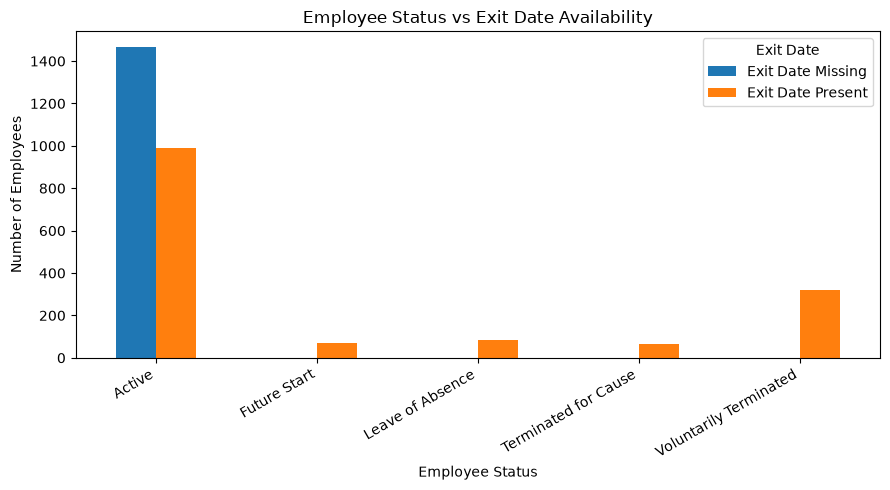

In [213]:
import matplotlib.pyplot as plt
status_exit = pd.crosstab(
    df["EmployeeStatus"],
    df["ExitDate"].notna()
).reindex(columns=[False, True], fill_value=0)

status_exit.columns = ["Exit Date Missing", "Exit Date Present"]

status_exit.plot(kind="bar", figsize=(9, 5))
plt.title("Employee Status vs Exit Date Availability")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Exit Date")
plt.tight_layout()
plt.show()

### 2. Workforce Distribution

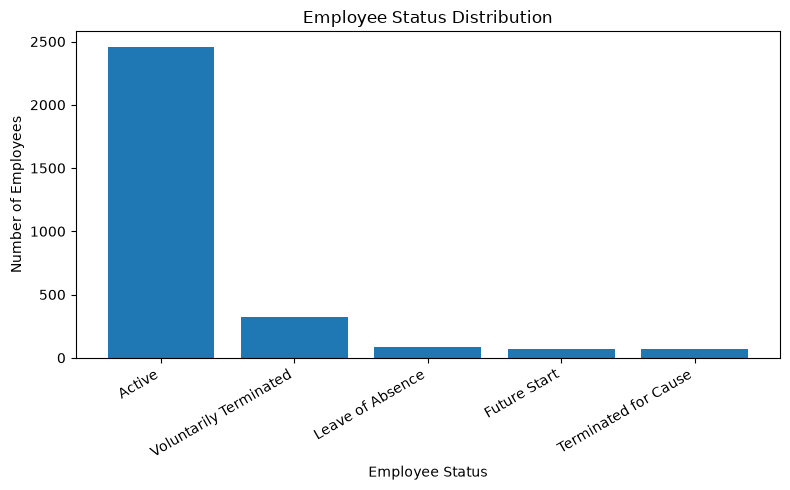

In [214]:
status_counts = df["EmployeeStatus"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values)
plt.title("Employee Status Distribution")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 3. Hiring Trends

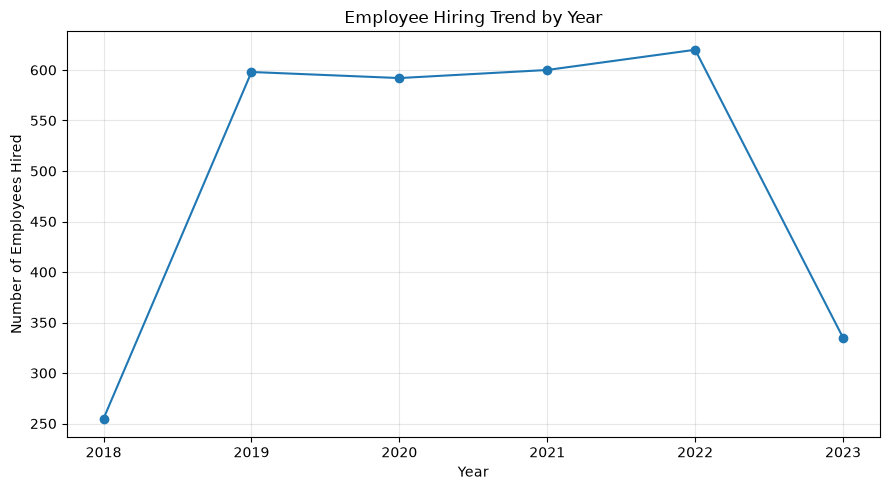

In [215]:
hiring = (
    df["StartDate"]
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))
plt.plot(hiring.index, hiring.values, marker="o")
plt.title("Employee Hiring Trend by Year")
plt.xlabel("Year")
plt.ylabel("Number of Employees Hired")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Employee Termination Analysis

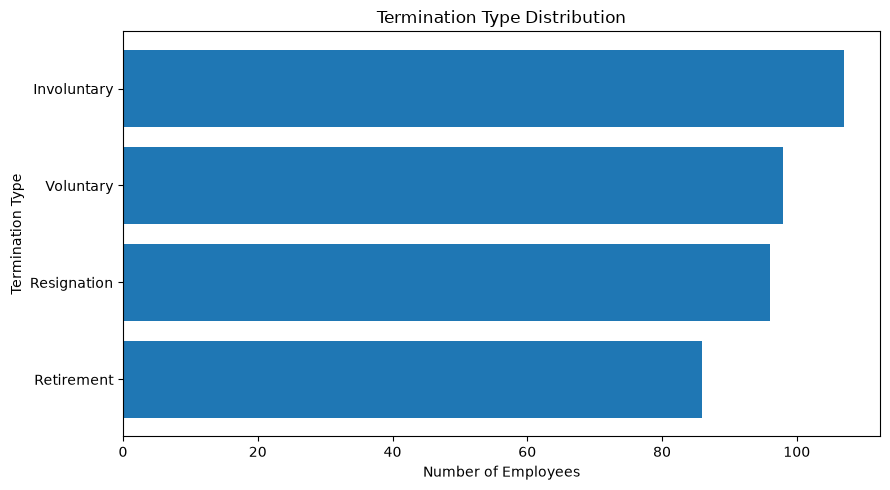

Total terminated employees: 387
TerminationType
Involuntary    107
Voluntary       98
Resignation     96
Retirement      86
Name: count, dtype: int64


In [222]:
terminated = df[
    df["EmployeeStatus"].isin(
        ["Voluntarily Terminated", "Terminated for Cause"]
    )
]

termination_counts = (
    terminated["TerminationType"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))
plt.barh(termination_counts.index, termination_counts.values)
plt.title("Termination Type Distribution")
plt.xlabel("Number of Employees")
plt.ylabel("Termination Type")
plt.tight_layout()
plt.show()
print("Total terminated employees:", len(terminated))
print(termination_counts.sort_values(ascending=False))

### 5. Workforce Status Proportions

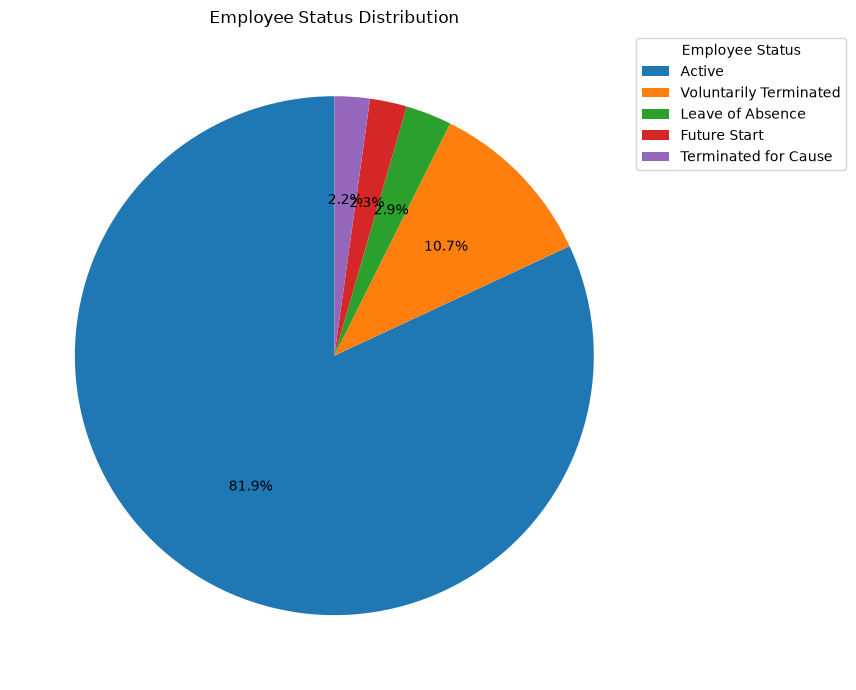

In [217]:

status_counts = df["EmployeeStatus"].value_counts()

plt.figure(figsize=(8, 7))

plt.pie(
    status_counts.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90
)

plt.legend(
    status_counts.index,
    title="Employee Status",
    loc="upper right",
    bbox_to_anchor=(1.3, 1)
)

plt.title("Employee Status Distribution")
plt.tight_layout()
plt.show()

In [218]:
output_path = "hr_analytics_cleaned.csv"
df.to_csv(output_path, index=False, date_format="%Y-%m-%d")
print("Cleaned CSV saved successfully:", output_path)
print("Final shape:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Cleaned CSV saved successfully: hr_analytics_cleaned.csv
Final shape: (3000, 38)
Remaining duplicate rows: 0
